# Lab03 — Exercise 2: Frozen DistilBERT và đánh giá nhị phân

Kết quả chính: frozen DistilBERT, train đủ **10 epoch**, chọn checkpoint **epoch 9 theo validation loss**, threshold **0.45 từ validation Macro-F1**. Test accuracy **82.83%**, Macro-F1 **82.82%**. Mục tiêu là giảm overfitting; không tuyên bố đây là accuracy cao nhất lịch sử.

Notebook này được thực thi ở `MODE="view"`: đọc artifact Kaggle đã kiểm toán, hiển thị PNG và bảng đã lưu; **không phải một lượt train GPU mới**. Train từ đầu bằng [notebook 08](08_kaggle_frozen_encoder_trial.ipynb). Báo cáo đầy đủ và câu hỏi bảo vệ: [walkthrough](../walkthrough_lab_03.md).

| Phase | Mục tiêu | Module/file tham chiếu | Artifact dùng trong report |
|---|---|---|---|
| 1 | Nguồn bằng chứng và audit | config/report.json, src/final_review.py | audit.json, manifests |
| 2 | Pretrained sentiment, tokenization | src/models/classifier.py | tokenizer/pipeline/manual PNG |
| 3 | Dataset đầy đủ và tokenization | src/datasets/loader.py | class distribution, token lengths |
| 4 | Feature engineering/augmentation | src/datasets/augmentation.py | before/after/counts PNG |
| 5 | Freeze và optimizer | src/training/frozen.py | freezing_and_optimizer.json |
| 6 | Train đủ 10 epoch | src/training/trainer.py | epoch_history, learning_curves.png |
| 7 | Chọn checkpoint và threshold | src/training/thresholds.py | validation threshold curves |
| 8 | Baseline và test | scripts/run_frozen_trial.py | confusion/ROC/PR/calibration |
| 9 | Phân tích lỗi, so sánh lịch sử | src/final_review.py | sample/per-class/comparison PNG |
| 10 | Save/load, artifact, giới hạn | scripts/publish_artifacts.py | published/index.md, manifest |

Mọi ảnh hiển thị đều được lưu trong `outputs/`. JSON giữ số liệu có thể tính lại; notebook trình bày hình và diễn giải trực tiếp. Không sửa byte run gốc để làm đẹp đường học.


## 1. Thiết lập chế độ xem và kiểm toán bằng chứng

Không tải dataset hoặc weights khi xem. Kiểm tra SHA256, đủ 10 epoch, chọn đúng minimum validation loss và tái tính threshold/metrics từ records.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown

MODE = "view"
assert MODE == "view", "Train riêng bằng notebook 08 trên Kaggle GPU."
start = Path.cwd().resolve()
LAB = next((p for p in (start, *start.parents) if (p/"config/report.json").is_file()), None)
if LAB is None:
    LAB = next((p/"labs/lab03" for p in (start,*start.parents) if (p/"labs/lab03/config/report.json").is_file()), None)
assert LAB is not None, "Mở notebook từ repository đã clone đầy đủ."
sys.path.insert(0, str(LAB.parents[1]))
from labs.lab03.src.final_review import audit_frozen_trial
from labs.lab03.src.evidence import verify_manifest
settings = json.loads((LAB/"config/report.json").read_text())
def read(path):return json.loads(Path(path).read_text())
def source(role):return LAB/"outputs/runs"/settings["runs"][role]
def show(folder, names):
    for name in names:
        path = Path(folder)/name
        assert path.is_file(), f"Thiếu artifact: {path}"
        display(Markdown(f"**{name}**")); display(Image(filename=str(path)))
TRIAL = source("frozen_trial")
REVIEW = source("final_review")
verify_manifest(REVIEW)
audit = audit_frozen_trial(TRIAL)
display(pd.DataFrame([{k:v for k,v in audit.items() if not isinstance(v,dict)}]))


,status,run_id,selected_epoch,threshold,test_samples,weights_loaded_locally,threshold_reselected_on_test,historical_test_previously_inspected
0,passed,20261027T095655Z_frozen_trial_d8d09116,9,0.45,1066,False,False,True


## 3. Dataset đầy đủ, EDA và tokenization

Rotten Tomatoes giữ official splits: **8.530 train / 1.066 validation / 1.066 test**; mỗi split cân bằng hai lớp. Tokenizer WordPiece lowercase theo pretrained backbone, max_length=128, dynamic padding theo batch. Không xóa `not`, `but` hoặc stopwords. EDA độ dài dùng train gốc: mean 27.37 tokens, max 78, không có mẫu train bị cắt ở 128. Thống kê này không khẳng định mọi heldout cũng dưới cutoff.


,train,validation,test
NEGATIVE,4265,533,533
POSITIVE,4265,533,533


,mean,max,truncated_fraction
0,27.368347,78,0.0


**class_distribution.png**

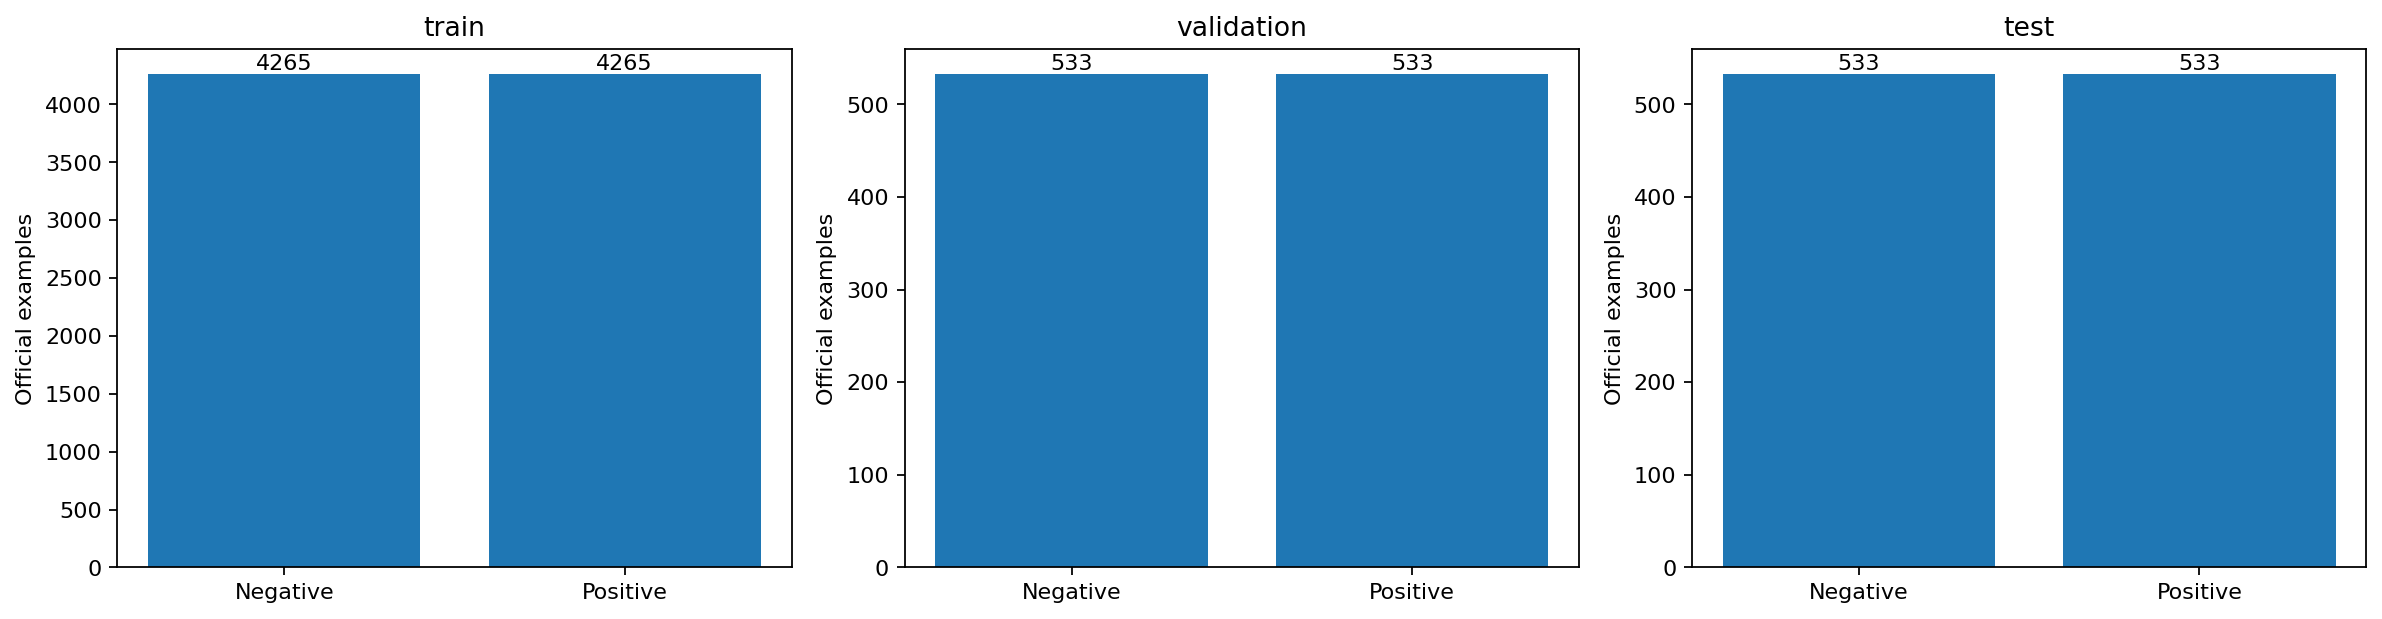

**token_length_distribution.png**

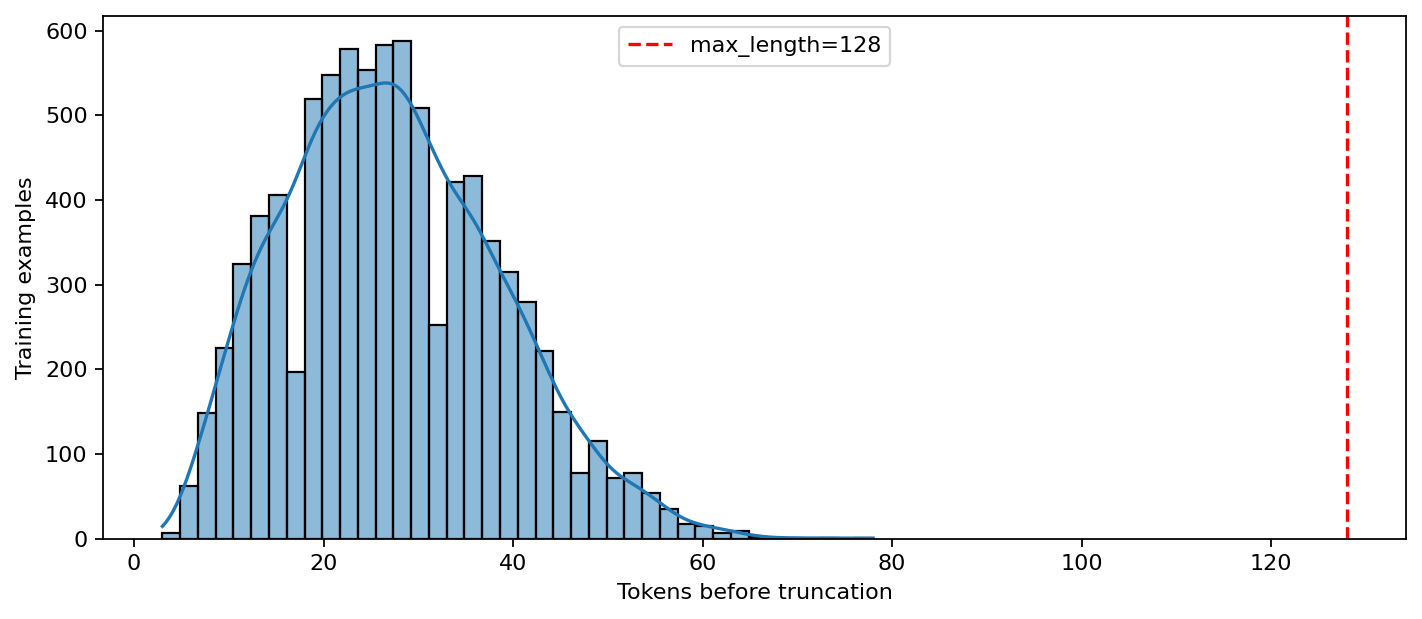

**train_examples.png**

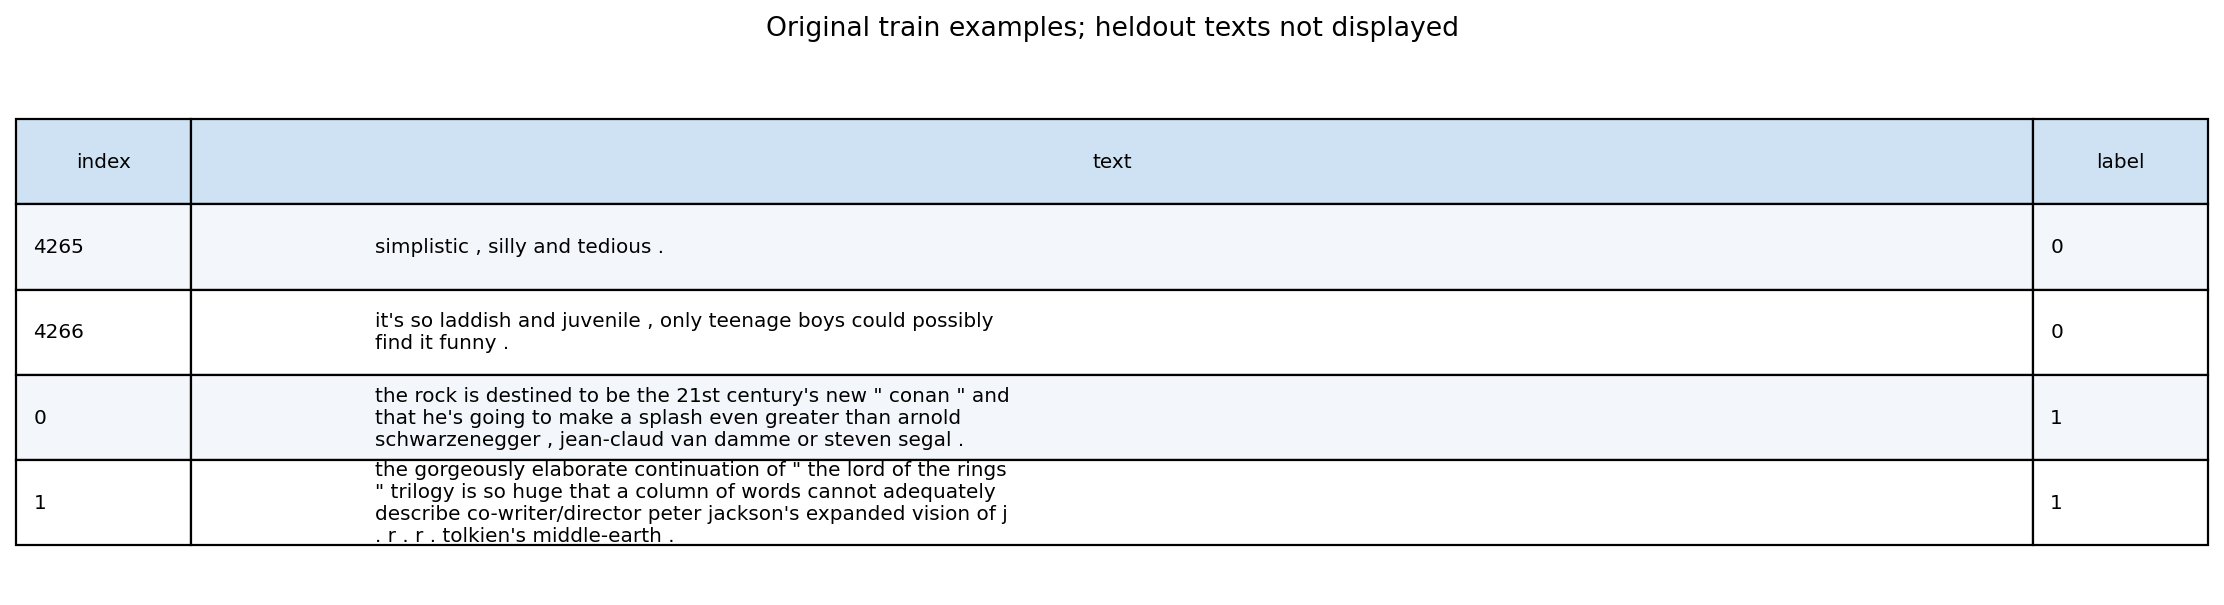

In [2]:
EDA = source("frozen_dataset_preview")
preview = read(EDA/"data_preview.json")
display(pd.DataFrame(preview["label_counts"]).rename(index={"0":"NEGATIVE","1":"POSITIVE"}))
display(pd.DataFrame([preview["train_token_lengths"]]))
show(EDA, ["class_distribution.png", "token_length_distribution.png", "train_examples.png"])


## 4. Feature engineering và tăng mẫu train có kiểm soát

DistilBERT dùng token IDs/attention mask, không nhận TF-IDF vectors. TF-IDF unigram/bigram là feature riêng của baseline. Augmentation thay một từ/cụm từ cùng cực tính, bỏ phủ định/tương phản, chống trùng và không đổi validation/test. Lượt này thêm **274 mẫu**, gồm 137 mỗi lớp: effective train **8.804**. Nhãn kế thừa là heuristic có thể nhiễu, không phải ground truth mới do con người gán. Không ép đủ quota 25% hoặc thêm 800 bản gần trùng.


,original_train_size,added_count,effective_train_size
0,8530,274,8804


**augmentation_counts.png**

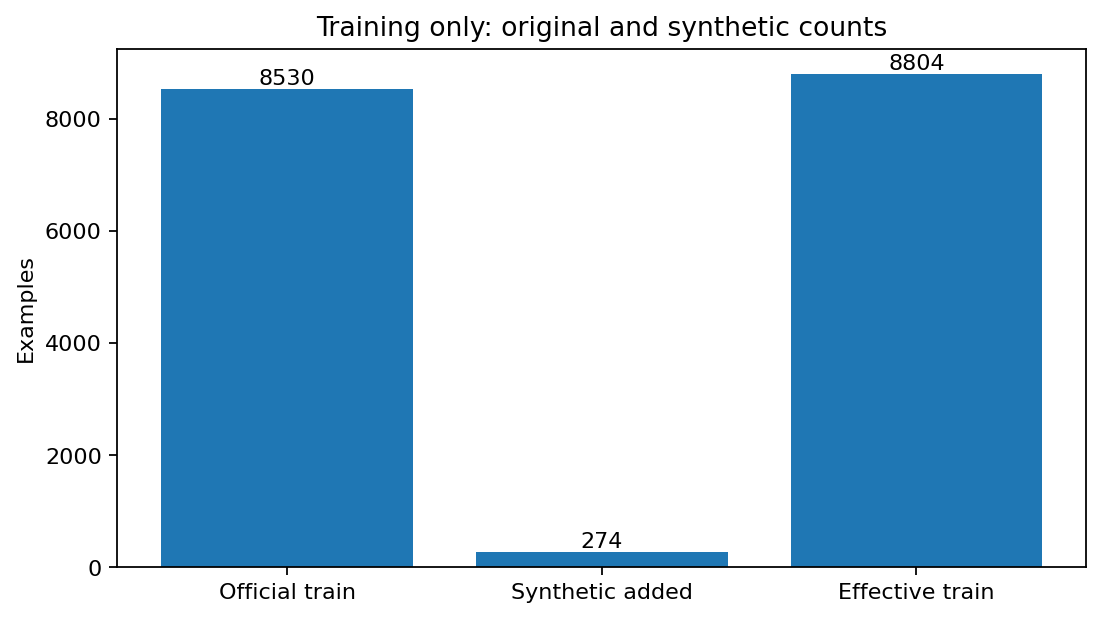

**augmentation_examples.png**

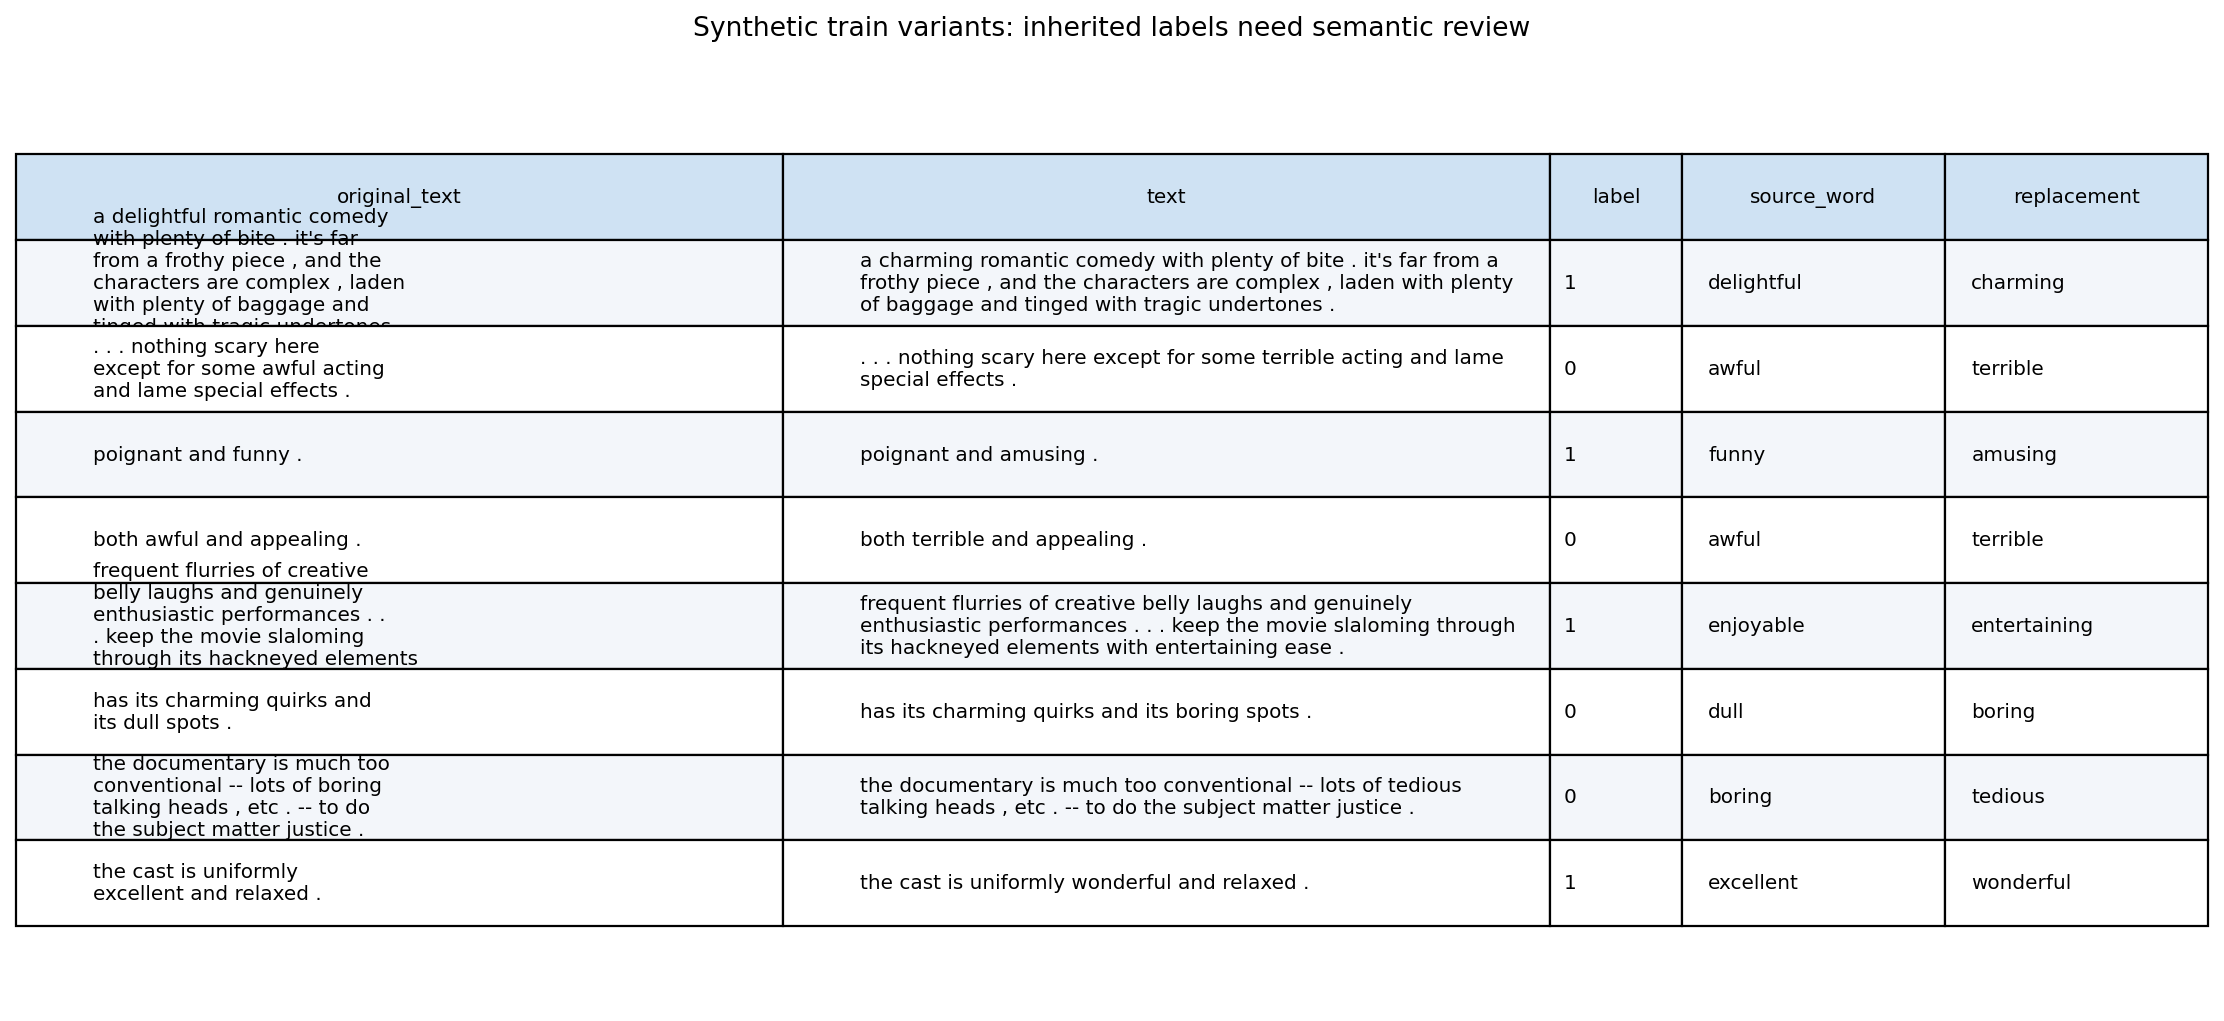

In [3]:
augmentation = read(TRIAL/"augmentation.json")
display(pd.DataFrame([{k:augmentation[k] for k in ["original_train_size","added_count","effective_train_size"]}]))
show(TRIAL, ["augmentation_counts.png", "augmentation_examples.png"])


## 5. Kiến trúc, đóng băng và optimizer

Đóng băng embedding và 4/6 tầng encoder đầu. Chỉ **14.767.874/66.955.010 tham số (22.06%)** được cập nhật. Encoder LR 2e-6, head LR 1e-5; warmup 10% rồi giảm tuyến tính. AdamW decay 0.1 cho trọng số, không decay bias/LayerNorm. Dropout encoder/attention/head: 0.2/0.2/0.4. Frozen parameters không đồng nghĩa dropout bị tắt trong lúc train; khi đo metrics, eval mode tắt dropout toàn bộ.


In [4]:
cfg = read(TRIAL/"config.json")["exercise2"]
freezing = read(TRIAL/"freezing_and_optimizer.json")
display(pd.DataFrame([{"total_parameters":freezing["total_parameters"],"trainable_parameters":freezing["trainable_parameters"],"frozen_encoder_layers":freezing["frozen_encoder_layers"]}]))
display(pd.DataFrame([{k:v for k,v in g.items() if k in ["lr","weight_decay","eps"]} for g in freezing["optimizer_groups"]]))


,total_parameters,trainable_parameters,frozen_encoder_layers
0,66955010,14767874,4


,lr,weight_decay,eps
0,0.000002,0.1,1.000000e-08
1,0.000002,0.0,1.000000e-08
2,0.000010,0.1,1.000000e-08
3,0.000010,0.0,1.000000e-08


## 6. Đường học đủ 10 epoch

Bảng có đúng 10 hàng; mỗi đường có 10 điểm nguyên epoch. Train/validation đều đo full split tương ứng trong eval mode. Train gồm cả 274 synthetic variants nên khoảng cách là chỉ báo mô tả, không phải hai mẫu độc lập hoàn toàn. Batch 16 trên 8.804 mẫu tạo 551 bước/epoch, 5.510 global steps. AMP bỏ qua 3 optimizer updates; global steps không bằng số cập nhật thành công.

Epoch 10: train loss **0.3581**, validation loss **0.3696**, train accuracy **84.25%**, validation accuracy **83.77%**. Gap accuracy **0.47 điểm phần trăm**; validation loss chỉ tăng 0.000294 từ epoch 9 tới 10. Chưa có dấu hiệu overfitting mạnh trong ngân sách này; không khẳng định vĩnh viễn không overfit hoặc mô hình đã tối ưu.


,epoch,step,train_loss_eval,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,learning_rate,epoch_runtime_seconds
0,1,551,0.612102,0.767151,0.612096,0.775797,0.775012,2.000000e-06,18.811370
1,2,1102,0.399959,0.818719,0.401842,0.819887,0.819872,1.778181e-06,18.313120
2,3,1653,0.384900,0.827351,0.387137,0.824578,0.824570,1.555959e-06,18.725699
3,4,2204,0.374508,0.833939,0.381047,0.833959,0.833799,1.334140e-06,18.806669
4,5,2755,0.369851,0.833598,0.376652,0.833959,0.833906,1.111918e-06,19.051578
5,6,3306,0.363106,0.839505,0.373288,0.834897,0.834783,8.896955e-07,18.647766
6,7,3857,0.362880,0.838483,0.371724,0.835835,0.835828,6.674733e-07,18.480643
7,8,4408,0.361536,0.839618,0.371199,0.837711,0.837710,4.456544e-07,18.620578
8,9,4959,0.357609,0.842117,0.369328,0.835835,0.835783,2.234321e-07,18.811372
9,10,5510,0.358071,0.842458,0.369622,0.837711,0.837679,1.209921e-09,19.155446


**learning_curves.png**

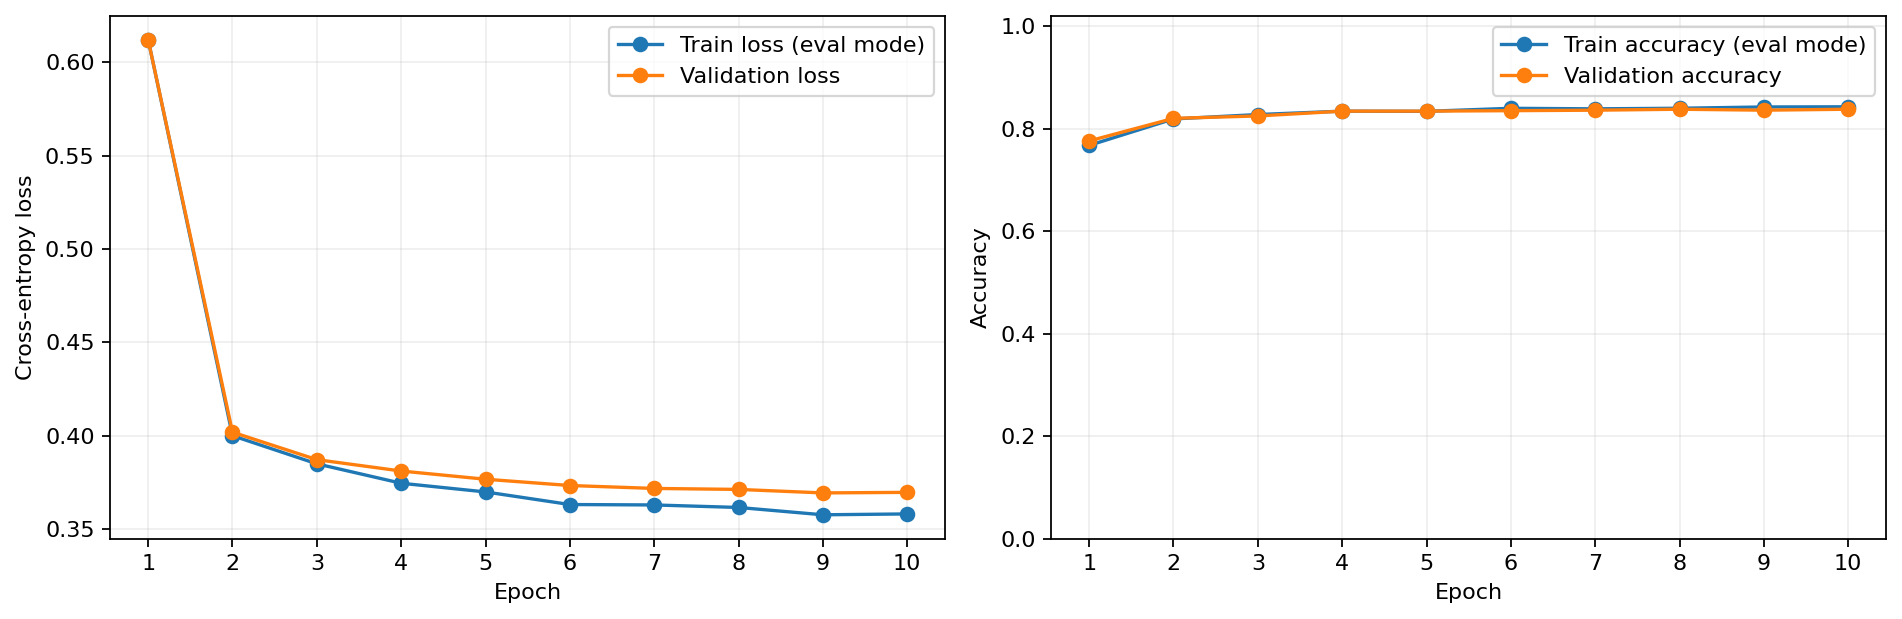

**generalization_gaps.png**

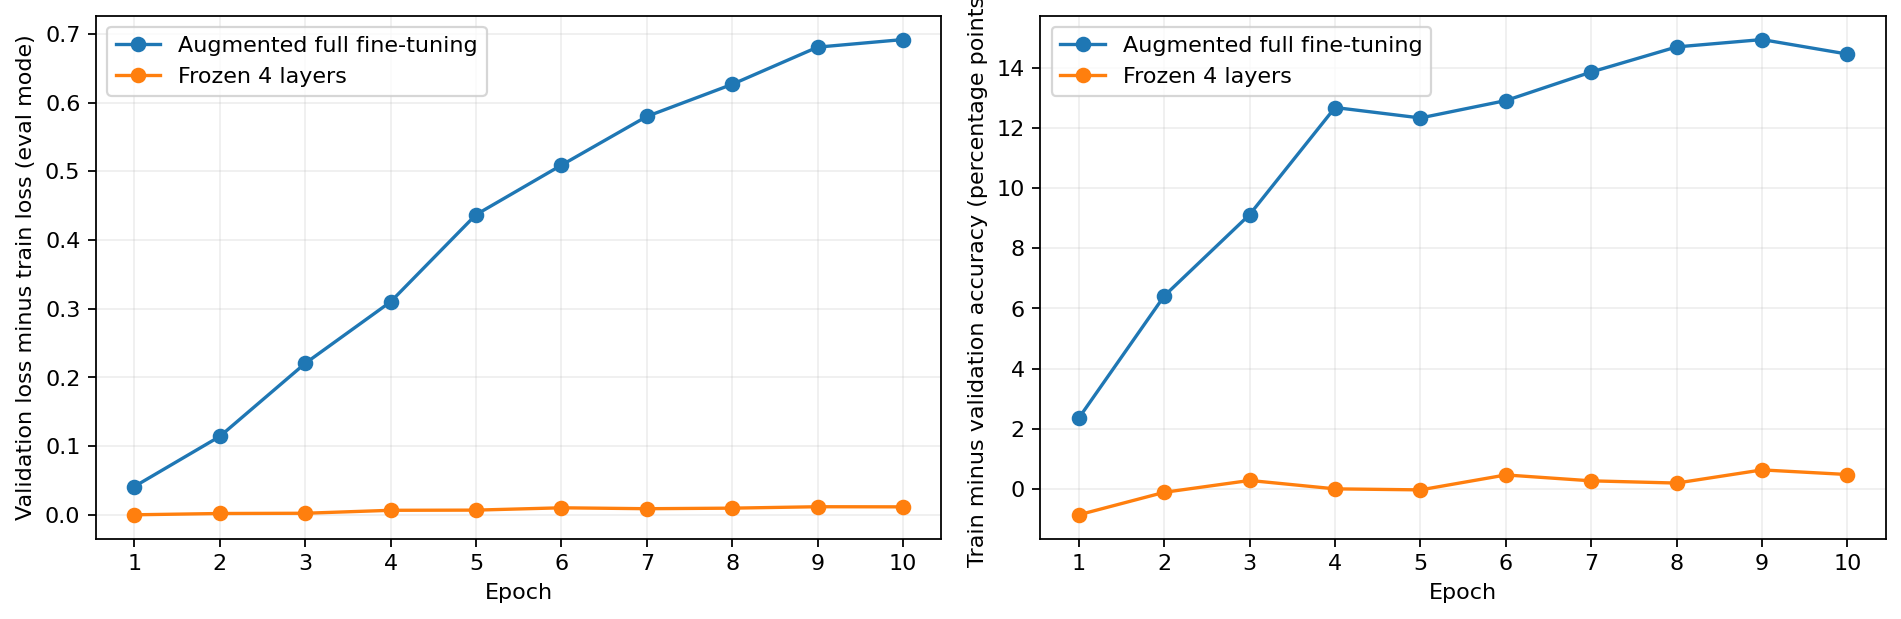

In [5]:
epochs = pd.DataFrame(read(TRIAL/"epoch_history.json"))
assert epochs["epoch"].tolist() == list(range(1,11))
display(epochs)
show(TRIAL, ["learning_curves.png"])
show(REVIEW, ["generalization_gaps.png"])


## 7. Checkpoint và validation threshold sweep

Giữ đủ 10 epoch để quan sát, nhưng dùng **epoch 9 / step 4959** vì validation loss nhỏ nhất **0.369328**. Đây là tiêu chí định trước; epoch 10 có validation accuracy cao hơn vẫn không được thay vào. Sau reload, quét 19 ngưỡng từ 0.05 đến 0.95 trên validation, tối đa Macro-F1; hòa thì gần 0.5 rồi ngưỡng nhỏ hơn. Chọn **0.45** và ghi frozen_selection trước test.


,completed_epochs,early_stopping,checkpoint_selection_metric,selected_epoch,best_step,best_validation_loss,global_step,amp_skipped_optimizer_steps,test_used_for_selection
0,10.0,False,validation_loss,9,4959,0.369328,5510,3,False


,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,0.50,0.835835,0.848249,0.818011,0.853659,0.146341,0.832856,0.835783,455,78,97,436,533,533,1066
1,0.45,0.840525,0.836735,0.846154,0.834897,0.165103,0.841418,0.840520,445,88,82,451,533,533,1066


**validation_threshold_curves.png**

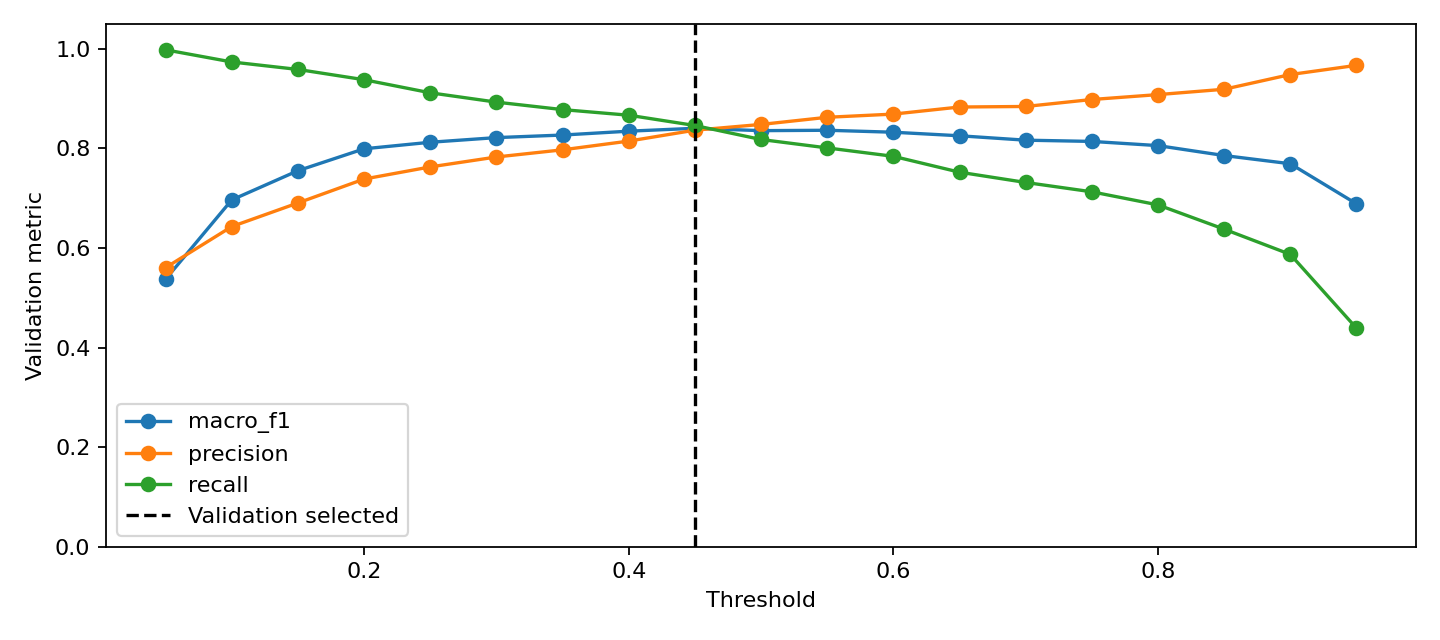

In [6]:
display(pd.DataFrame([read(TRIAL/"selection_summary.json")]))
policy = read(TRIAL/"decision_threshold.json")
display(pd.DataFrame([policy["baseline_metrics"],policy["selected_metrics"]]))
show(TRIAL, ["validation_threshold_curves.png"])


## 8. Test cố định và baseline

TF-IDF + logistic regression fit train-only trên cùng augmented pool, chọn C/threshold bằng validation. Frozen model tại threshold 0.45 đúng **883/1.066**, accuracy **82.83%**, Binary F1 **83.23%**, Macro-F1 **82.82%**. Threshold 0.5 có cùng số đúng nhưng phân bố lỗi khác; giữ 0.45 theo validation, không đổi vì test Macro-F1 của 0.5 nhỉnh hơn.

Ma trận threshold 0.45: **TN=429, FP=104, FN=79, TP=454**. Negative recall 80.49%, Positive recall 85.18%; 19.51% review Negative bị gọi Positive. Threshold thấp tăng positive recall, đồng thời tăng false positives. Confusion matrix được chuẩn hóa theo hàng, vẫn hiện số đếm.


,model,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,TF-IDF,0.50,0.789869,0.792060,0.786116,0.793621,0.206379,0.789077,0.789866,423,110,114,419,533,533,1066
1,Frozen DistilBERT threshold 0.5,0.50,0.828330,0.825279,0.833021,0.823640,0.176360,0.829132,0.828326,439,94,89,444,533,533,1066
2,Frozen DistilBERT validation threshold,0.45,0.828330,0.813620,0.851782,0.804878,0.195122,0.832264,0.828236,429,104,79,454,533,533,1066


,class,precision,recall,f1-score,support,TPR,FPR
0,NEGATIVE,0.844488,0.804878,0.824207,533.0,0.804878,0.148218
1,POSITIVE,0.813620,0.851782,0.832264,533.0,0.851782,0.195122


**confusion_matrix.png**

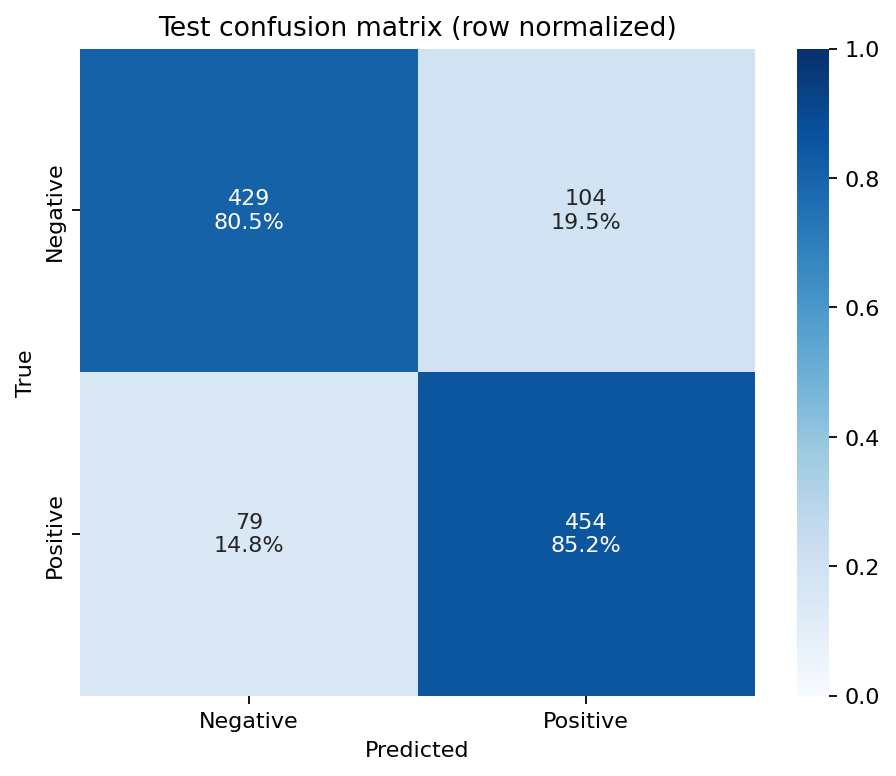

**per_class_metrics.png**

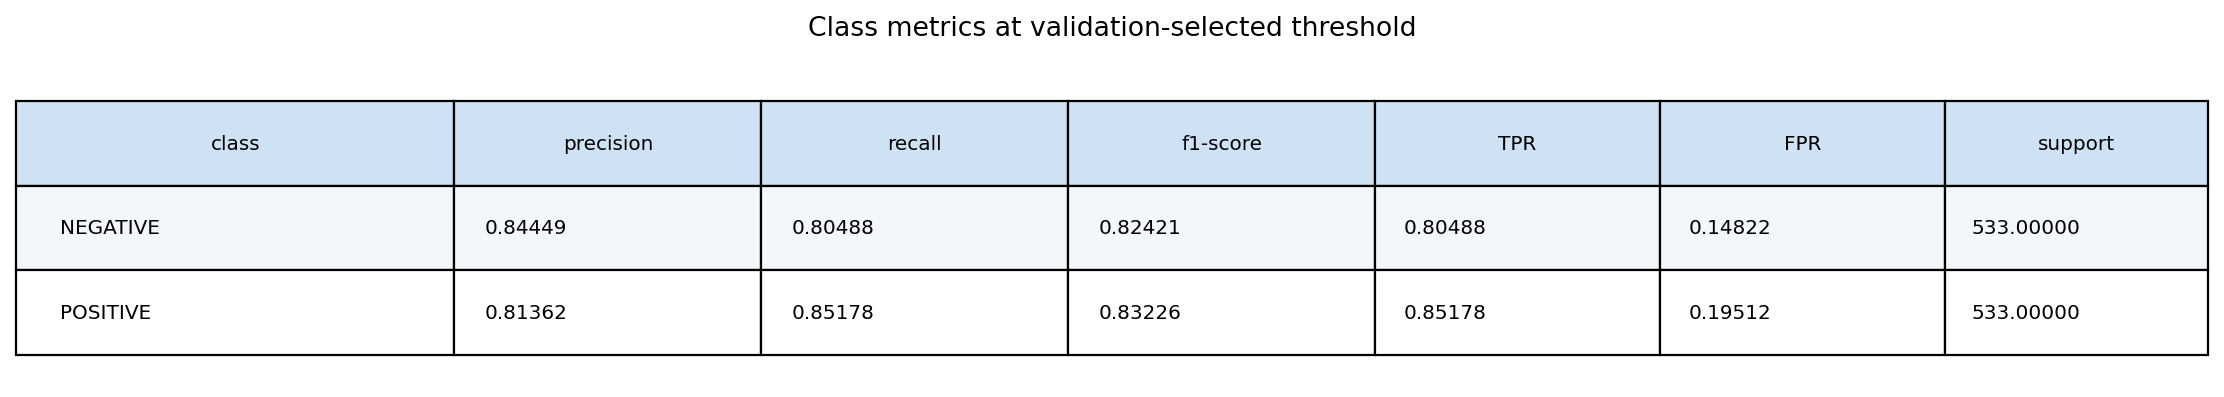

In [7]:
display(pd.DataFrame(read(TRIAL/"test_comparison.json")))
display(pd.DataFrame(read(REVIEW/"per_class_metrics.json")))
show(TRIAL, ["confusion_matrix.png"])
show(REVIEW, ["per_class_metrics.png"])


### Chất lượng xác suất và giới hạn confidence

Test loss **0.412560**, ROC-AUC **0.8981**, ECE **0.03795**, Brier **0.12818**. Confidence ECE thấp hơn lượt full fine-tuning, nhưng phụ thuộc cách chia bin và không bảo đảm từng dự đoán đúng. ROC/PR là chẩn đoán sau khi khóa policy, không dùng chúng để chọn lại threshold trên test. Bootstrap CI có điều kiện trên model/threshold đã cố định, không bao gồm biến thiên seed hoặc quá trình chọn hyperparameter.


,roc_auc,average_precision,brier_score,confidence_ece,nll,threshold,selection_split,bootstrap_repeats,ci_scope
0,0.898115,0.906652,0.128183,0.03795,0.412561,0.45,validation,2000,"fixed model, fixed threshold, stratified test ..."


**roc_pr_curves.png**

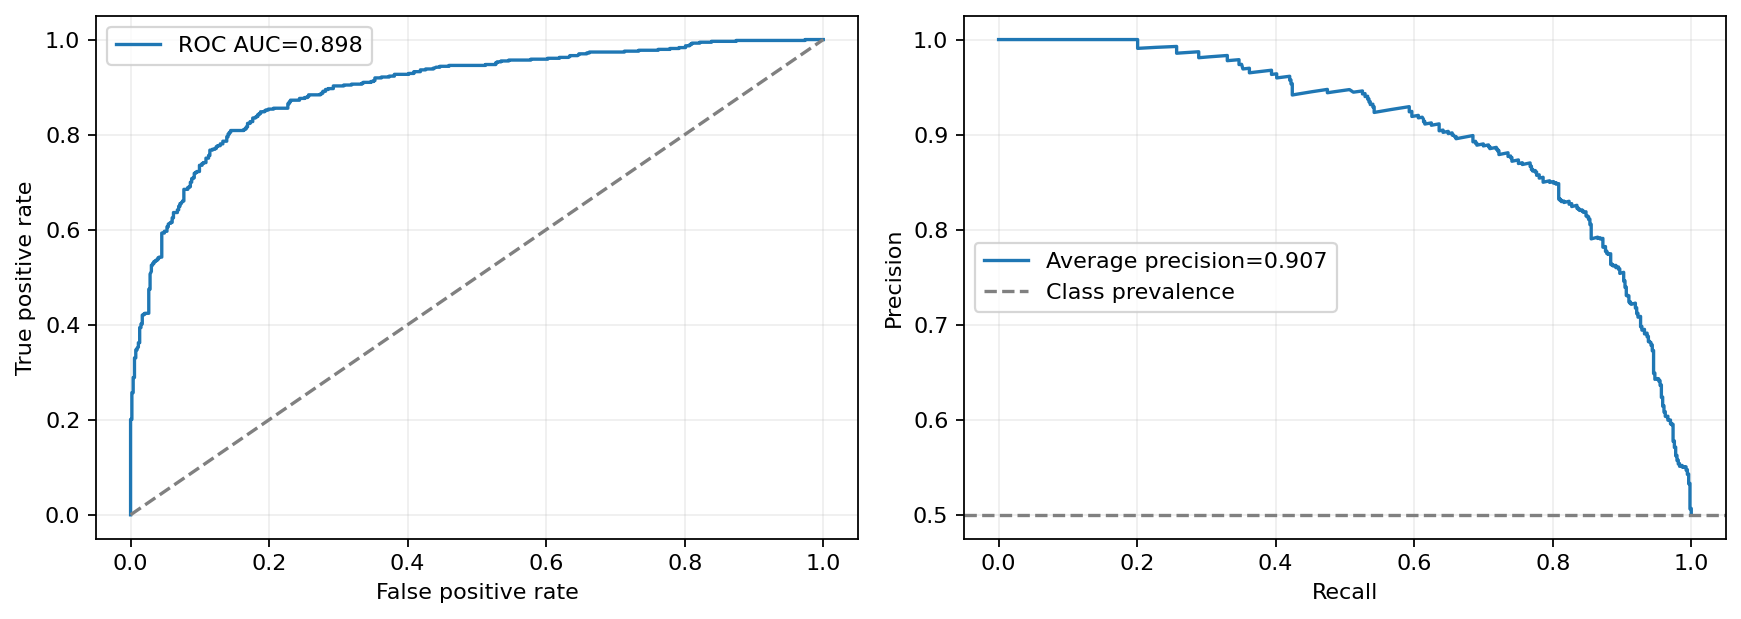

**calibration_confidence.png**

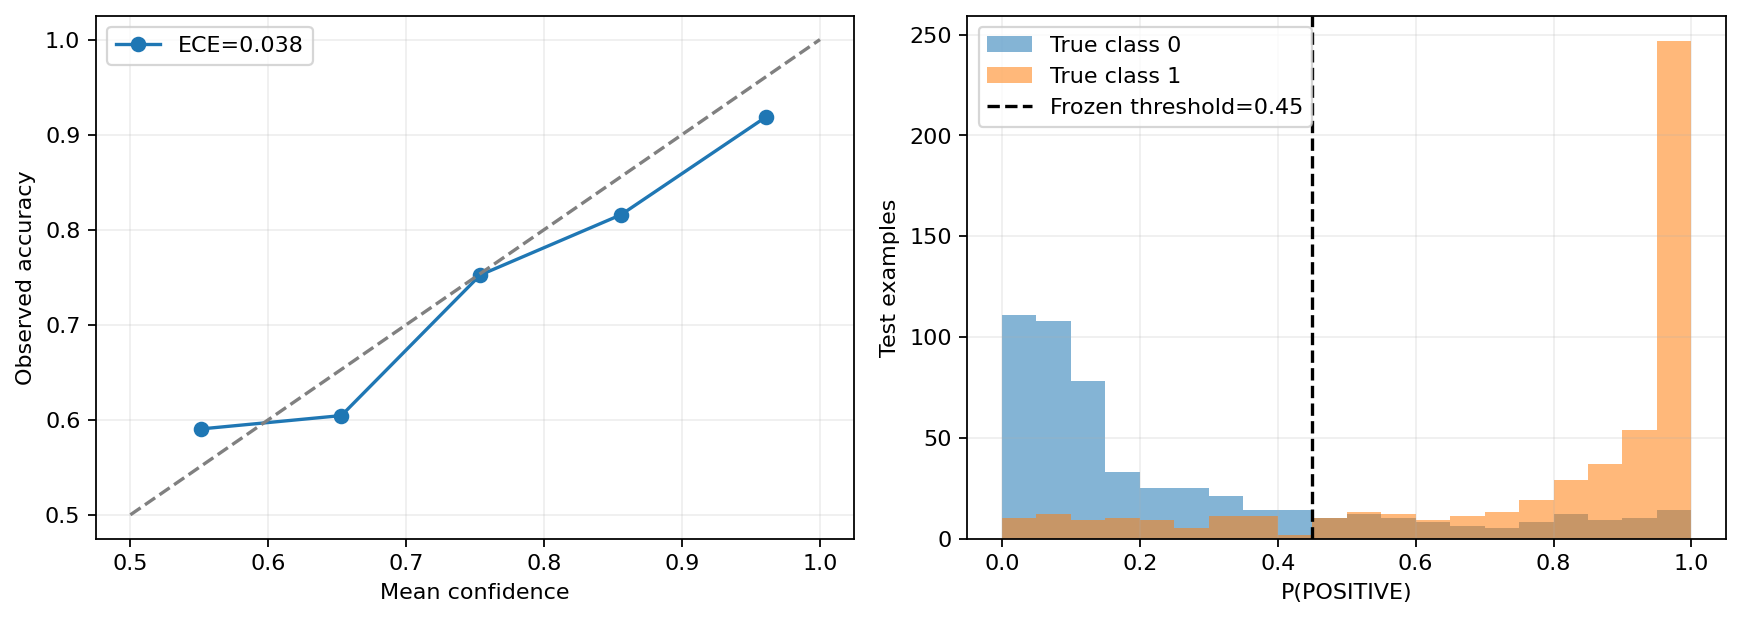

In [8]:
diagnostics = read(TRIAL/"probability_diagnostics.json")
display(pd.DataFrame([{k:v for k,v in diagnostics.items() if isinstance(v,(int,float,str))}]))
show(TRIAL, ["roc_pr_curves.png", "calibration_confidence.png"])


## 9. So sánh lịch sử và phân tích lỗi

Bản frozen giảm gap và test loss nhưng accuracy thấp hơn bản augmented full fine-tuning **1.31 điểm phần trăm (14 mẫu)**. Không chọn mô hình bằng cách tìm hàng có test accuracy cao nhất. Bản frozen là cấu hình chính theo mục tiêu đã chốt giảm overfitting; các run khác là lịch sử mô tả. Freeze, dropout, LR và tiêu chí checkpoint thay đổi cùng lúc nên không quy tác động riêng cho một yếu tố. Một seed chưa cho phép tuyên bố cải thiện thống kê.


,experiment,run_id,threshold,accuracy,precision,recall,binary_f1,macro_f1,TN,FP,FN,TP,test_loss,confidence_ece,brier_score
0,Unregularized 10 epoch,20261026T184219Z_study_94f2ba7b,0.50,0.833959,0.838403,0.827392,0.832861,0.833952,448,85,92,441,0.798076,0.146071,0.150674
1,Augmented full fine-tuning,20261027T083010Z_study_99bce559,0.65,0.841463,0.839552,0.844278,0.841908,0.841462,447,86,83,450,0.625951,0.130603,0.142356
2,Frozen 4 layers,20261027T095655Z_frozen_trial_d8d09116,0.45,0.828330,0.813620,0.851782,0.832264,0.828236,429,104,79,454,0.412560,0.037950,0.128183


**experiment_comparison.png**

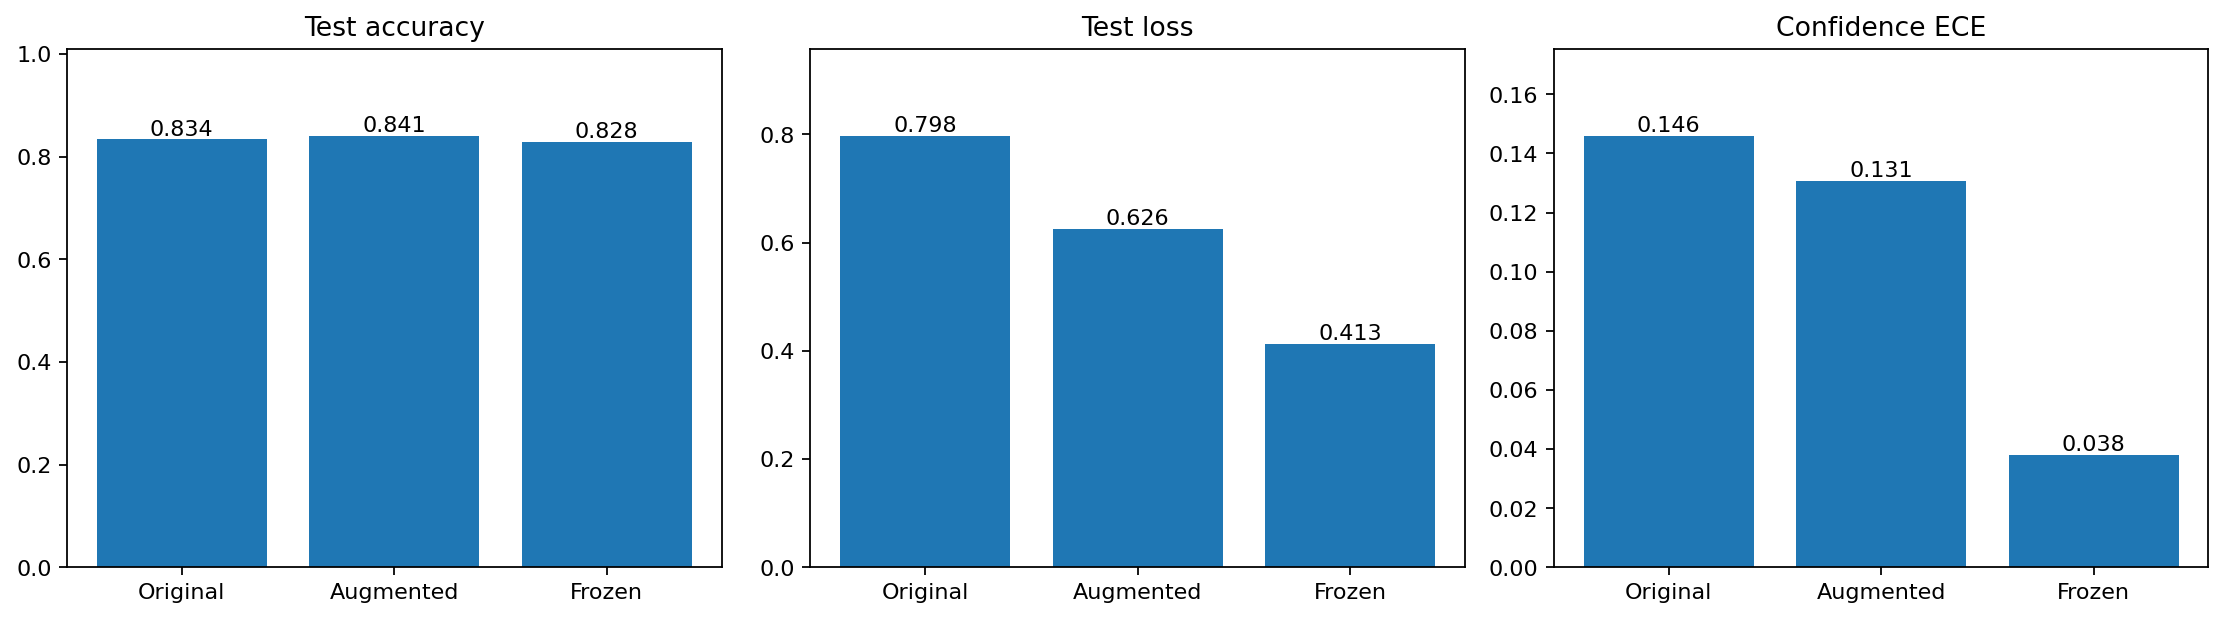

**sample_predictions.png**

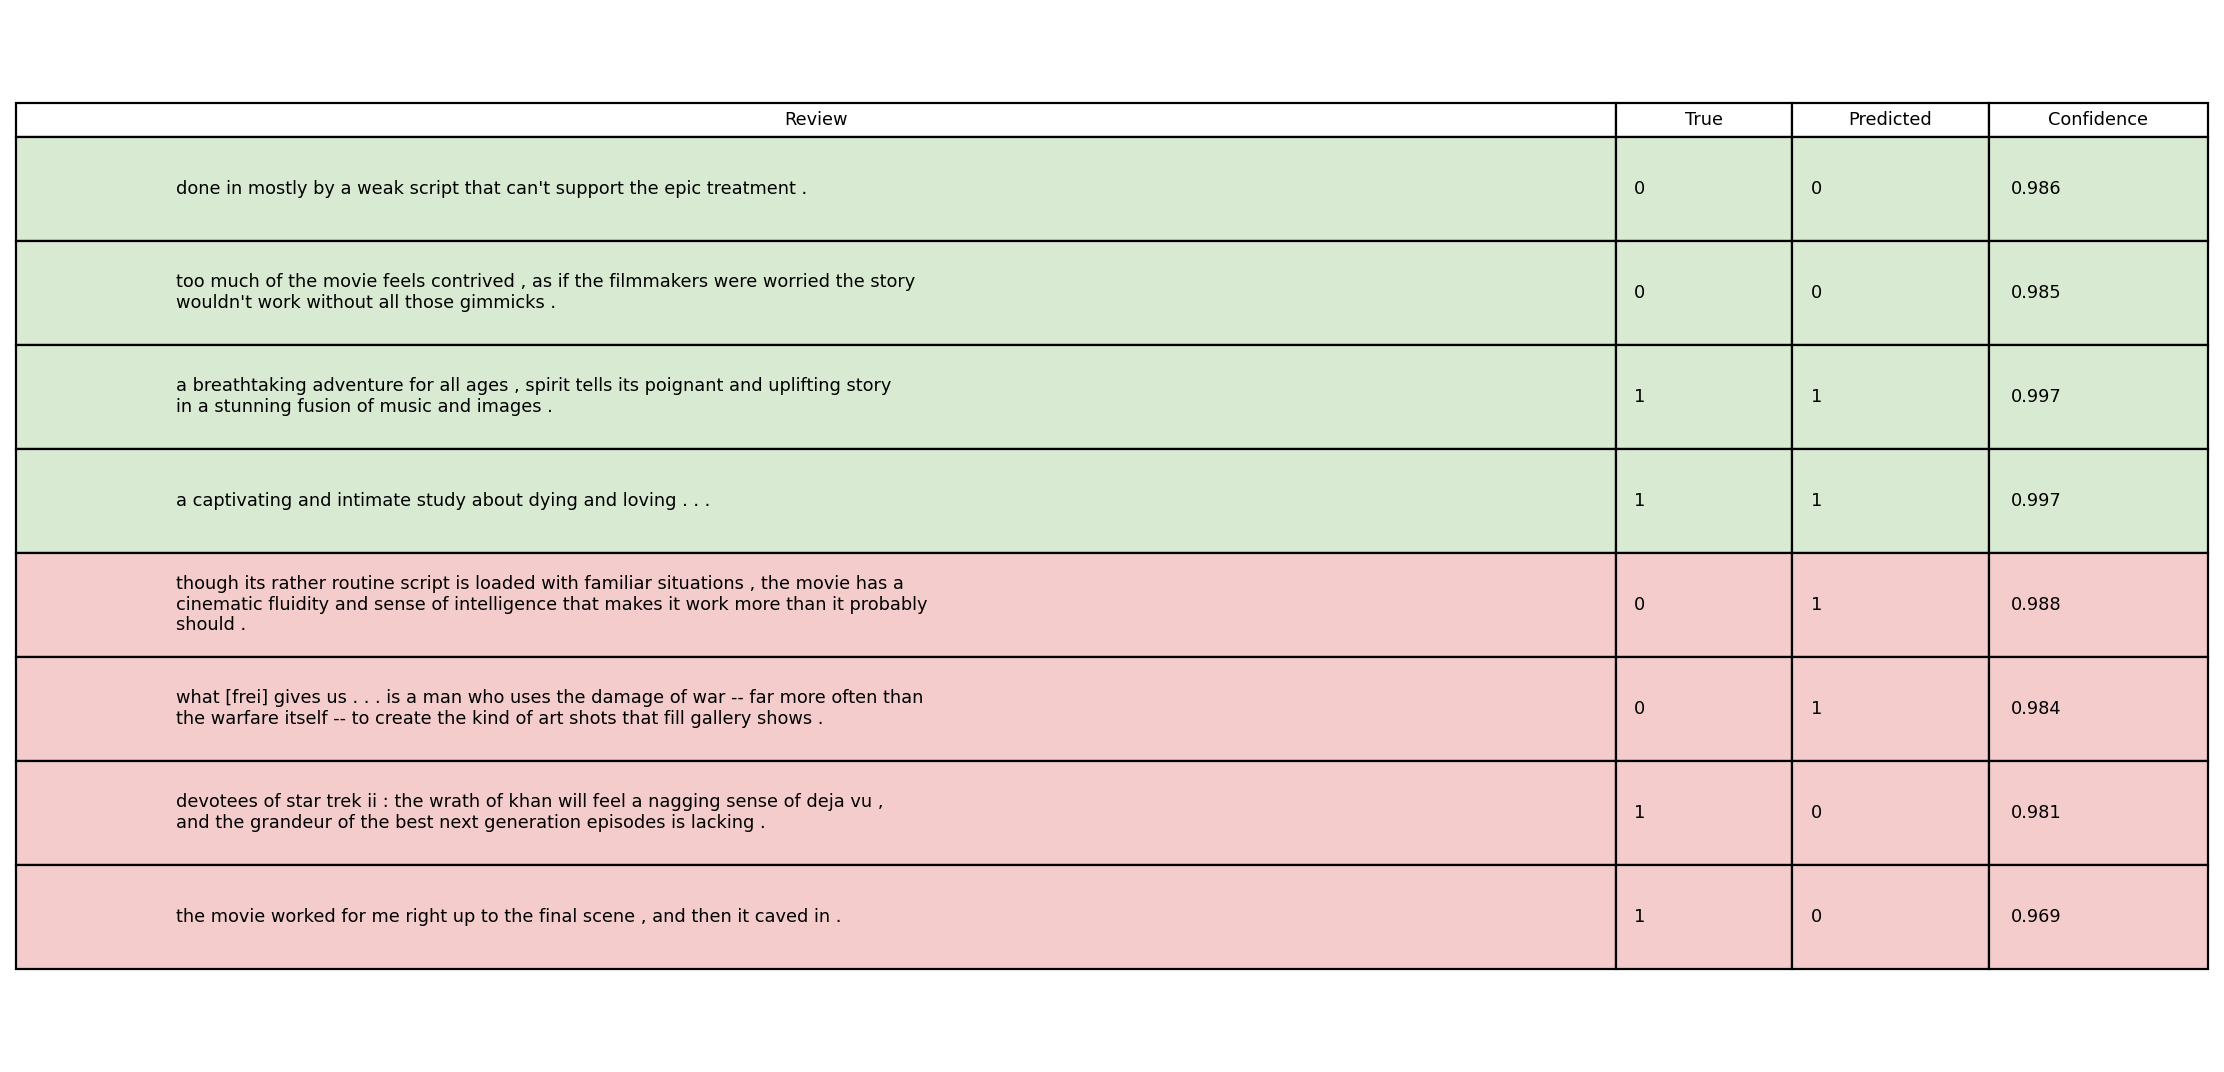

,text,true_label,predicted_label,confidence,correct
0,done in mostly by a weak script that can't sup...,0,0,0.986125,True
1,"too much of the movie feels contrived , as if ...",0,0,0.985300,True
2,"a breathtaking adventure for all ages , spirit...",1,1,0.997444,True
3,a captivating and intimate study about dying a...,1,1,0.997232,True
4,though its rather routine script is loaded wit...,0,1,0.987616,False
5,what [frei] gives us . . . is a man who uses t...,0,1,0.983940,False
6,devotees of star trek ii : the wrath of khan w...,1,0,0.980747,False
7,the movie worked for me right up to the final ...,1,0,0.969324,False


In [9]:
display(pd.DataFrame(read(REVIEW/"comparison.json")))
show(REVIEW, ["experiment_comparison.png", "sample_predictions.png"])
samples = pd.DataFrame(read(REVIEW/"sample_predictions.json"))
display(samples[["text","true_label","predicted_label","confidence","correct"]])


### Đọc ví dụ lỗi

Đối chiếu câu, nhãn thật và dự đoán ở bảng trên. Các câu có đánh giá ngầm, nhiều mệnh đề hoặc tham chiếu văn hóa có thể khó; đó là giả thuyết ngôn ngữ cần đọc thủ công, không phải nguyên nhân mô hình đã đo được. Các ví dụ được lấy từ test đã đánh giá để báo cáo lỗi, không đưa lại vào training hoặc thiết kế augmentation của lượt này.

## 10. Save/load, artifact và tái lập

Artifact `reload_check.json` ghi weights_exact_match và forward CPU FP32 trên **bốn câu validation**; không mô tả đó là kiểm chứng toàn bộ test sau reload. ZIP review không có weights: audit hiện tại tính lại records/threshold/metrics và kiểm tra SHA256, không load lại checkpoint. Checkpoint ZIP giữ riêng để inference/re-evaluation. Thư mục `outputs/published/` chứa ảnh/bảng đã chọn cho report; không cần extract JSON rồi viết lại code vẽ cho mỗi lần làm báo cáo.

Checkpoint ZIP cũ cần chạy `scripts/prepare_frozen_checkpoint.py --model-path <best_model đã giải nén>` để gắn policy/config sau khi đối chiếu SHA256. Sau đó dùng `scripts/infer.py --model-path <best_model> --text <câu mới>`. Làm trên bản checkpoint lưu riêng, không sửa raw run; hướng dẫn đầy đủ ở README Mục 9.


In [10]:
reload_check = read(TRIAL/"reload_check.json")
display(pd.DataFrame([{k:v for k,v in reload_check.items() if k!="predictions"}]))
display(pd.DataFrame(reload_check["predictions"]))
from labs.lab03.scripts.publish_artifacts import publish_artifacts
published = publish_artifacts()
display(Markdown(f"Artifact report: `{published.relative_to(LAB)}`. Xem `index.md`, `metrics_summary.json` và `artifact_catalog.json`."))


,weights_exact_match,execution
0,True,"CPU FP32, clean forward methods"


,text,label,score,probabilities
0,compassionately explores the seemingly irrecon...,POSITIVE,0.984190,"[0.01580999232828617, 0.984190046787262]"
1,the soundtrack alone is worth the price of adm...,POSITIVE,0.605683,"[0.39431703090667725, 0.6056829690933228]"
2,rodriguez does a splendid job of racial profil...,POSITIVE,0.986418,"[0.013582521118223667, 0.9864175319671631]"
3,beneath the film's obvious determination to sh...,POSITIVE,0.982791,"[0.01720915548503399, 0.9827908277511597]"


Artifact report: `outputs/published`. Xem `index.md`, `metrics_summary.json` và `artifact_catalog.json`.

### Câu hỏi bảo vệ nhanh

- **Tại sao train đủ 10 epoch nhưng chọn epoch 9?** Ngân sách quan sát và tiêu chí checkpoint là hai quyết định khác nhau; chọn validation loss thấp nhất.
- **Tại sao train accuracy chỉ 84%?** Phần lớn backbone đóng băng và LR nhỏ giảm khả năng ghi nhớ; chưa đủ bằng chứng để gọi là tối ưu hay kết luận chắc chắn underfit.
- **Tại sao không tăng dropout tiếp?** Regularization quá mạnh có thể giảm khả năng thích nghi; đường gần nhau không phải mục tiêu duy nhất.
- **Tại sao threshold 0.45?** Được chọn bằng validation Macro-F1, không chọn bằng test hoặc buộc khác 0.5.
- **Có data leakage không?** Official splits giữ nguyên, baseline fit train-only, augmentation train-only; text heldout chỉ dùng chặn trùng. Không có audit semantic/pretraining contamination hoàn chỉnh.
- **Có tái lập chính xác trên mọi GPU không?** Seed và môi trường được ghi, nhưng một lượt chạy chưa chứng minh mọi nền tảng cho bitwise equality.

Kết luận: đáp ứng hai Exercise và yêu cầu quan sát 10 epoch, có threshold sweep và evidence report. Frozen trial giảm mạnh dấu hiệu overfitting quan sát được; đổi lại accuracy thấp hơn full fine-tuning. Không bảo đảm không overfit ở dữ liệu khác hoặc ngân sách dài hơn.
